# Olist E-commerce Analysis: delivery, revenue and retention charts
Charts for the project README. Data comes from the SQLite database `olist.db`, built by `load_data.py`. SQL queries are in the `0X_*.sql` files.

**imports and connection**

In [17]:
import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect("olist.db")
os.makedirs("charts", exist_ok=True)

**load delivered orders into a DataFrame**

In [18]:
query = """
SELECT o.order_id,
       c.customer_state,
       o.order_delivered_customer_date AS delivered,
       o.order_estimated_delivery_date AS estimated,
       r.review_score
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
LEFT JOIN (SELECT order_id, AVG(review_score) AS review_score
           FROM order_reviews
           GROUP BY order_id) r ON r.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
"""
df = pd.read_sql_query(query, conn, parse_dates=["delivered", "estimated"])
print(df.shape)
df.head()

(96470, 5)


,order_id,customer_state,delivered,estimated,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,SP,2017-10-10 21:25:13,2017-10-18,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,BA,2018-08-07 15:27:45,2018-08-13,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,GO,2018-08-17 18:06:29,2018-09-04,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,2017-12-02 00:28:42,2017-12-15,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,2018-02-16 18:17:02,2018-02-26,5.0


**add the late flag and verify against SQL**

In [19]:
df["is_late"] = df["delivered"].dt.normalize() > df["estimated"].dt.normalize()
df["days_vs_estimate"] = (df["delivered"].dt.normalize() - df["estimated"].dt.normalize()).dt.days
print(round(df["is_late"].mean() * 100, 2))   # should be 6.77

6.77


**first chart, review score by delivery status**

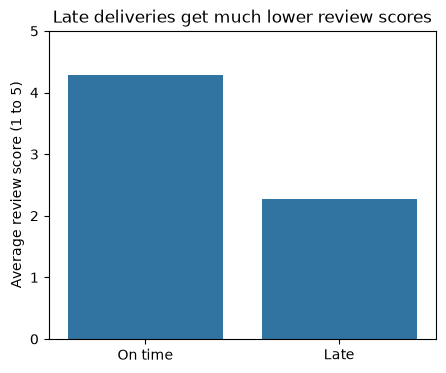

In [20]:
df["delivery_status"] = df["is_late"].map({True: "Late", False: "On time"})

plt.figure(figsize=(5, 4))
sns.barplot(data=df, x="delivery_status", y="review_score", errorbar=None, order=["On time", "Late"])
plt.title("Late deliveries get much lower review scores")
plt.xlabel("")
plt.ylabel("Average review score (1 to 5)")
plt.ylim(0, 5)
plt.savefig("charts/review_by_delivery.png", dpi=150, bbox_inches="tight")
plt.show()

**monthly revenue trend**

13181027.13


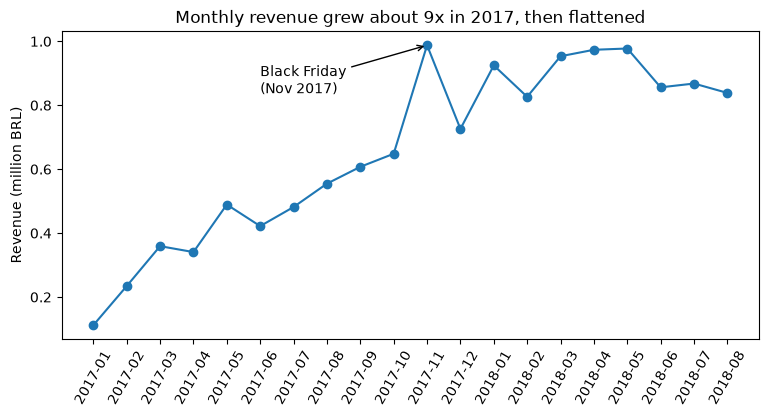

In [21]:
rev_query = """
SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS order_month,
       SUM(oi.price) AS revenue
FROM orders o
JOIN order_items oi ON oi.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND strftime('%Y-%m', o.order_purchase_timestamp) BETWEEN '2017-01' AND '2018-08'
GROUP BY order_month
ORDER BY order_month
"""
rev = pd.read_sql_query(rev_query, conn)
rev["revenue_m"] = rev["revenue"] / 1e6
print(round(rev["revenue"].sum(), 2))   # should be 13181027.13

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(rev["order_month"], rev["revenue_m"], marker="o")
bf = rev.index[rev["order_month"] == "2017-11"][0]
ax.annotate("Black Friday\n(Nov 2017)", xy=(bf, rev.loc[bf, "revenue_m"]),
            xytext=(bf - 5, rev.loc[bf, "revenue_m"] - 0.15),
            arrowprops=dict(arrowstyle="->"))
ax.set_title("Monthly revenue grew about 9x in 2017, then flattened")
ax.set_ylabel("Revenue (million BRL)")
ax.set_xlabel("")
plt.xticks(rotation=60)
plt.savefig("charts/monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

**late rate by state**

  customer_state  orders  late_pct
0             MA     717      17.4
1             CE    1279      13.8
2             BA    3256      12.2
3             RJ   12350      12.1
4             PA     946      11.2
5             ES    1995      10.7
6             PB     517      10.4
7             MS     701       9.7
8             PE    1593       9.6
9             SC    3546       8.2


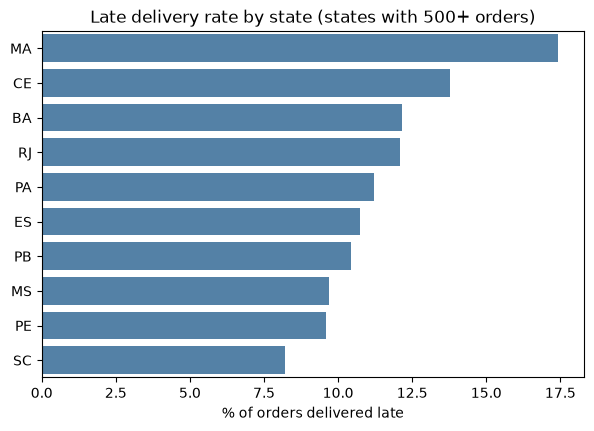

In [22]:
state = (df.groupby("customer_state")
           .agg(orders=("order_id", "count"),
                late_pct=("is_late", lambda s: s.mean() * 100))
           .query("orders >= 500")
           .sort_values("late_pct", ascending=False)
           .head(10)
           .reset_index())
print(state.round(1))

plt.figure(figsize=(7, 4.5))
sns.barplot(data=state, y="customer_state", x="late_pct", color="steelblue")
plt.title("Late delivery rate by state (states with 500+ orders)")
plt.xlabel("% of orders delivered late")
plt.ylabel("")
plt.savefig("charts/late_rate_by_state.png", dpi=150, bbox_inches="tight")
plt.show()

**cohort retention heatmap**

(19, 6)


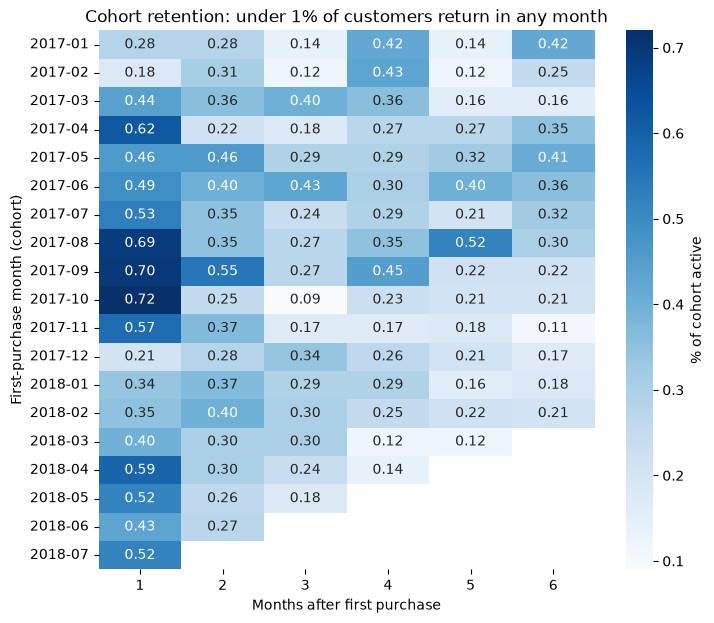

In [23]:
cohort_query = """
WITH customer_orders AS (
    SELECT c.customer_unique_id,
           strftime('%Y-%m', o.order_purchase_timestamp) AS order_month
    FROM orders o
    JOIN customers c ON c.customer_id = o.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id, order_month
),
first_month AS (
    SELECT customer_unique_id, MIN(order_month) AS cohort_month
    FROM customer_orders
    GROUP BY customer_unique_id
),
cohort_sizes AS (
    SELECT cohort_month, COUNT(*) AS cohort_size
    FROM first_month
    GROUP BY cohort_month
),
activity AS (
    SELECT f.cohort_month,
           co.customer_unique_id,
           (CAST(substr(co.order_month, 1, 4) AS INTEGER) * 12 + CAST(substr(co.order_month, 6, 2) AS INTEGER))
         - (CAST(substr(f.cohort_month, 1, 4) AS INTEGER) * 12 + CAST(substr(f.cohort_month, 6, 2) AS INTEGER))
           AS month_number
    FROM customer_orders co
    JOIN first_month f ON f.customer_unique_id = co.customer_unique_id
)
SELECT a.cohort_month,
       a.month_number,
       ROUND(COUNT(DISTINCT a.customer_unique_id) * 100.0 / cs.cohort_size, 2) AS retention_pct
FROM activity a
JOIN cohort_sizes cs ON cs.cohort_month = a.cohort_month
WHERE a.cohort_month >= '2017-01'
  AND a.month_number <= 6
GROUP BY a.cohort_month, a.month_number
"""
ret = pd.read_sql_query(cohort_query, conn)

grid = (ret[ret["month_number"] >= 1]
          .pivot(index="cohort_month", columns="month_number", values="retention_pct"))
print(grid.shape)

plt.figure(figsize=(8, 7))
sns.heatmap(grid, annot=True, fmt=".2f", cmap="Blues", cbar_kws={"label": "% of cohort active"})
plt.title("Cohort retention: under 1% of customers return in any month")
plt.xlabel("Months after first purchase")
plt.ylabel("First-purchase month (cohort)")
plt.savefig("charts/cohort_retention_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()